PROGETTO 3 MODULO 3 


Implementare e confrontare due diversi algoritmi di classificazione, K-Nearest
Neighbors (KNN) e Support Vector Machine (SVM), dopo aver ridotto la di-
mensionalit`a del dataset Wine utilizzando la PCA.

1 Data Exploration & Preprocessing
• Caricamento e Analisi del dataset e fornire un’analisi descrittiva iniziale
(i.e. df.describe(), df.dtypes)
• Standardization delle feature (X) per garantire che tutti gli attributi
abbiano media zero e deviazione standard unitaria

2 Data Dimensionality Reduction
• Applicare la PCA (Principal Component Analysis) sui dati standardizzati
• Ridurre la dimensionalit`a a 2 componenti principali (n components=2)
per facilitare la visualizzazione

3 Addestramento & Valutazione
• Inizializzare due modelli:
1. K-Nearest Neighbors (KNN) con n neighbors=5
2. Support Vector Machine (SVM) con kernel=’linear’
• Addestrare entrambi i modelli utilizzando il dataset ridotto a 2 componenti
• Calcolare e stampare l’Accuracy Score di entrambi i modelli sull’intero set
di dati ridotto

4 Analisi & Visualizzazione
• Generare un grafico con due subplot per confrontare i risultati visivi
• Plottare i data points colorati in base alla loro classe di appartenenza
(target)
• Visualizzare i decision boundary dei modelli (KNN e SVM)

In [2]:
#PUNTO 1 

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine

In [3]:
data = load_wine()
X = data.data
y = data.target


In [4]:
display(pd.DataFrame(X, columns = data.feature_names))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0


In [5]:
display(pd.DataFrame(y, columns = ["target"]))


,target
0,0
1,0
2,0
3,0
4,0
...,...
173,2
174,2
175,2
176,2


In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [ ]:

#punto 2 
pca = PCA(n_components = 2, random_state=42)
X_pca = pca.fit_transform(X_scaled)



In [8]:
#punto 3 confronto tra modelli di classificazione 

knn_clf = KNeighborsClassifier(n_neighbors=5)
knn_clf.fit(X_pca, y)
y_pred_knn= knn_clf.predict(X_pca)

accuracy_knn = accuracy_score(y, y_pred_knn)
print(f"ACCURACY SCORE KNN:{accuracy_knn:.2f}")


svm_clf = SVC(kernel="linear")
svm_clf.fit(X_pca, y)
y_pred_svm = svm_clf.predict(X_pca)

accuracy_svm = accuracy_score(y, y_pred_svm)
print(f"ACCURACY SCORE SVM:{accuracy_svm:.2f}")


ACCURACY SCORE KNN:0.97
ACCURACY SCORE SVM:0.97


In [10]:
#punto 4 .

x_min, x_max = X_pca[:,0].min() - 0.5, X_pca[:,0].max() + 0.5
y_min, y_max = X_pca[:,1].min() - 0.5, X_pca[:,1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

Z = knn_clf.predict(np.c_[xx.ravel(), yy.ravel()])
S = svm_clf.predict(np.c_[xx.ravel(), yy.ravel()])

Z = Z.reshape(xx.shape)
S = S.reshape(xx.shape)



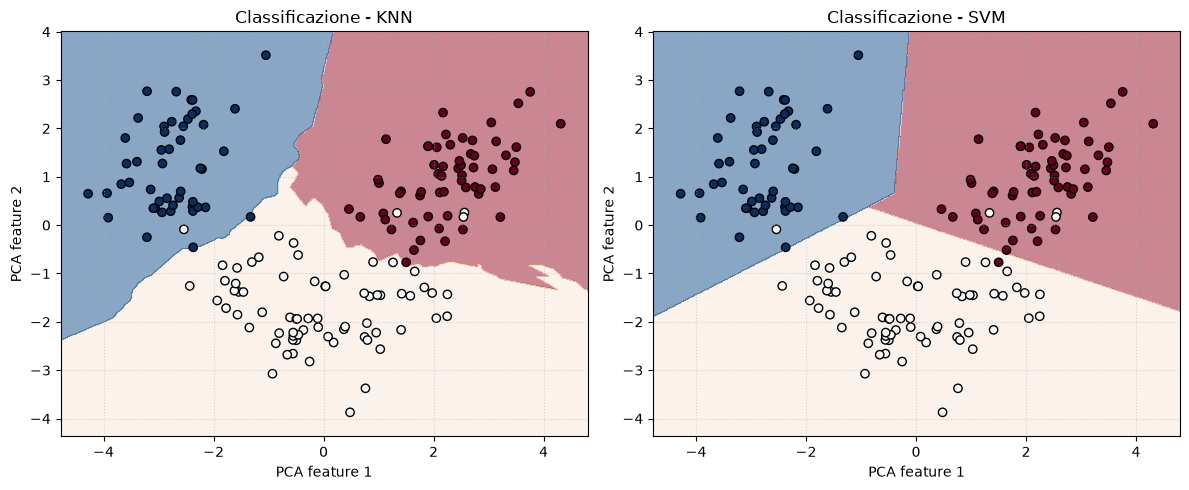

In [12]:
fig, (ax1,ax2) = plt.subplots(1,2, figsize=(12,5))
ax1.contourf(xx, yy, Z, alpha = 0.5, cmap= plt.cm.RdBu)
ax1.scatter(X_pca[:,0], X_pca[:,1], c = y, edgecolors = "k", cmap =plt.cm.RdBu )
ax1.set_title("Classificazione - KNN")
ax1.set_xlabel("PCA feature 1")
ax1.set_ylabel("PCA feature 2")
ax1.set_xlim(xx.min(), xx.max())
ax1.set_ylim(yy.min(), yy.max())
ax1.grid(True, linestyle=":", alpha=0.5)


ax2.contourf(xx, yy, S, alpha = 0.5, cmap= plt.cm.RdBu)
ax2.scatter(X_pca[:,0], X_pca[:,1], c = y, edgecolors = "k", cmap =plt.cm.RdBu )
ax2.set_title("Classificazione - SVM")
ax2.set_xlabel("PCA feature 1")
ax2.set_ylabel("PCA feature 2")
ax2.set_xlim(xx.min(), xx.max())
ax2.set_ylim(yy.min(), yy.max())
ax2.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()


